In [1]:
import sys; sys.path.append("..")
import json, joblib, warnings, numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from xgboost import XGBClassifier
from src.features import get_splits, make_preprocessor
from src.business import realized_net, expected_benefit, gains_table
from src.explain import shap_by_feature, top_reasons
from src.segments import assign_segments, segment_matrix, name_segment

X_train, X_test, y_train, y_test = get_splits("../data/raw/telco_churn.csv")
params = json.load(open("../models/xgb_best_params.json"))

champ = Pipeline([("pre", make_preprocessor()),
                  ("clf", XGBClassifier(**params, eval_metric="logloss",
                                        tree_method="hist", random_state=42, n_jobs=1))]).fit(X_train, y_train)
bench = Pipeline([("pre", make_preprocessor()),
                  ("clf", LogisticRegression(C=0.1, max_iter=2000))]).fit(X_train, y_train)

for name, m in [("XGB tuned (champion)", champ), ("LogReg C=0.1 (benchmark)", bench)]:
    p = m.predict_proba(X_test)[:, 1]
    print("%-24s ROC-AUC %.4f | PR-AUC %.4f | Brier %.4f" % (
        name, roc_auc_score(y_test, p), average_precision_score(y_test, p), brier_score_loss(y_test, p)))

XGB tuned (champion)     ROC-AUC 0.8459 | PR-AUC 0.6611 | Brier 0.1356
LogReg C=0.1 (benchmark) ROC-AUC 0.8413 | PR-AUC 0.6285 | Brier 0.1385


In [2]:
p = champ.predict_proba(X_test)[:, 1]
print(gains_table(y_test, p).round(3)[["customers", "churners", "churn_rate", "lift", "cum_capture"]].head(4))

SAVE_RATE, OFFER_COST = 0.25, 50          # same illustrative assumptions as notebook 07
monthly = X_test["MonthlyCharges"].values
for label, mask in [("Contact everyone", np.ones(len(p), bool)),
                    ("Threshold 0.5", p >= 0.5),
                    ("Expected-benefit rule", expected_benefit(p, monthly, SAVE_RATE, OFFER_COST) > 0)]:
    net = realized_net(y_test, monthly, mask, SAVE_RATE, OFFER_COST)
    print("%-22s contacted %4d | net $%8.0f | $%.1f per customer in the book" % (
        label, mask.sum(), net, net / len(p)))

        customers  churners  churn_rate   lift  cum_capture
decile                                                     
1             140       105       0.750  2.826        0.281
2             141        82       0.582  2.191        0.500
3             141        61       0.433  1.630        0.663
4             141        45       0.319  1.202        0.783
Contact everyone       contacted 1409 | net $   11195 | $7.9 per customer in the book
Threshold 0.5          contacted  282 | net $   29067 | $20.6 per customer in the book
Expected-benefit rule  contacted  579 | net $   39597 | $28.1 per customer in the book


In [3]:
scaler, km = joblib.load("../models/segments.joblib")
prof = segment_matrix(X_train); prof["segment"] = assign_segments(X_train, scaler, km)
names = prof.groupby("segment").mean().apply(name_segment, axis=1)

seg_test = assign_segments(X_test, scaler, km)
pd.DataFrame({"segment": [names[s] for s in seg_test], "churn": y_test.values}) \
  .groupby("segment")["churn"].agg(["mean", "count"]).round(3)

,mean,count
segment,,
Loyal power users,0.111,352
"Mid-value, month-to-month",0.281,317
"New fiber, month-to-month",0.516,428
No-internet / phone only,0.080,312


Contract           0.688
tenure             0.346
InternetService    0.255
OnlineSecurity     0.244
TechSupport        0.161
PaymentMethod      0.154
MonthlyCharges     0.149
is_new_customer    0.115
dtype: float32


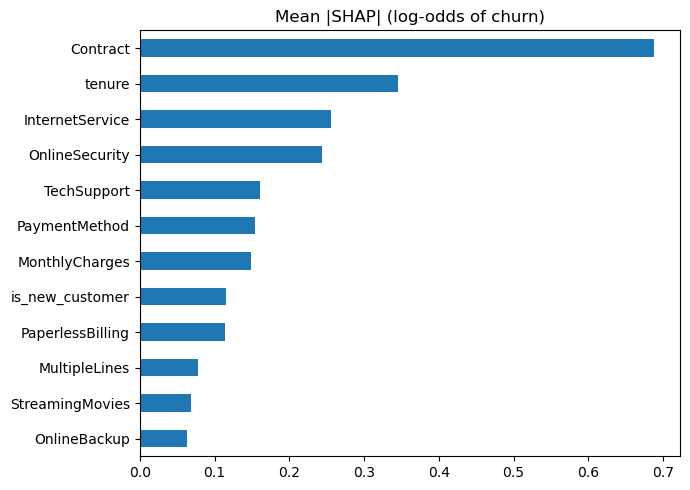

Churn probability: 0.040
[('Contract', 'Two year', -1.299), ('tenure', 72, -0.751), ('MonthlyCharges', 114.05, 0.349)]


In [4]:
sv, base = shap_by_feature(champ, X_train)          # log-odds, grouped back to original columns
imp = sv.abs().mean().sort_values(ascending=False)
print(imp.head(8).round(3))

imp.head(12).sort_values().plot(kind="barh", figsize=(7, 5), title="Mean |SHAP| (log-odds of churn)")
plt.tight_layout(); plt.savefig("../reports/figures/shap_importance.png", dpi=150); plt.show()

# one customer's top reasons
i = X_test.index[0]
sv_one, _ = shap_by_feature(champ, X_test.loc[[i]])
print("Churn probability: %.3f" % champ.predict_proba(X_test.loc[[i]])[0, 1])
print(top_reasons(sv_one.iloc[0], X_test.loc[i], n=3))

In [5]:
joblib.dump(champ, "../models/churn_model.joblib")
config = {"model": "XGBoost (tuned)", "features": list(X_train.columns),
          "save_rate": SAVE_RATE, "offer_cost": OFFER_COST,
          "test_roc_auc": round(roc_auc_score(y_test, p), 4),
          "test_pr_auc": round(average_precision_score(y_test, p), 4)}
json.dump(config, open("../models/model_config.json", "w"), indent=2)